# Initialising DyNeMo with N-FINDR (finding the corners)

This notebook explains a way to set DyNeMo's **starting mode covariances** from the data, available as
`init_method="nfindr"` (or `Model.nfindr_initialization`):

- **The problem.** With its default start, DyNeMo can get stuck in a worse solution: a weak mode
  dies, or two true modes end up merged in one fitted mode while another true mode is split in two.
  Starting from the true covariances gives a lower free energy, so this is an optimisation failure,
  not something the data can't support.
- **The idea.** Under DyNeMo's own model, the covariance of any short window of data is a weighted
  average of the mode covariances. So the windows form a cloud whose **corners are the modes**. We
  find the corners before training starts and give them to DyNeMo as its starting covariances.
- **The method.** N-FINDR, a standard way to find the corners of such a cloud ("endmember extraction"
  in hyperspectral imaging), followed by a least-squares fit that uses every window.

Contents: 1. DyNeMo recap. 2. What goes wrong with the default start. 3. The key fact, with a
2-channel picture. 4. The procedure, step by step. 5. Training DyNeMo from three starts.
6. Why it works. 7. Limitations. 8. How to use it.

Everything here is simulated inside the notebook. It needs a version of osl-dynamics with
`nfindr_initialization` for DyNeMo (branch `dynemo-nfindr-initialisation`). Section 5 trains DyNeMo
three times, which takes about 20 minutes on 4 CPUs.

## 1. What DyNeMo assumes

At each time point $t$ the data $x_t$ (one value per channel) is modelled as

$$x_t \sim \mathcal{N}(0, C_t), \qquad C_t = \sum_{k=1}^{K} \alpha_{tk}\, D_k, \qquad \alpha_{tk} \ge 0,\ \ \sum_k \alpha_{tk} = 1 .$$

- $D_k$ is the covariance of mode $k$ (learnt).
- $\alpha_t$ says how much of each mode is present at time $t$. An inference RNN reads the data and
  gives $\alpha$; a model RNN gives a prior on how $\alpha$ evolves. Training minimises the
  variational free energy (negative log-likelihood plus a KL term).

So the covariance at any moment is a **mixture** of the $K$ mode covariances. That one fact is what
the initialisation uses.

## 2. What goes wrong with the default start

**The default start.** Every mode covariance starts as $D_k = \mathrm{diag}(1 + \epsilon_k)$, with
$\epsilon_k$ small noise. All modes start almost identical. Then `random_subset_initialization`
trains a few copies for 2 epochs and keeps the one with the lowest loss.

**What happens next.** KL annealing keeps the KL weight near zero for the first part of training, so
$\alpha$ is unconstrained and the modes compete to explain the data, like a soft clustering that
starts from identical centres:

- the strong modes (large swings in $\alpha$) are claimed first;
- the leftover fitted modes end up **splitting** a strong mode, **merging** two weak ones, or **dying**
  ($\alpha_k \approx 0$, so its covariance gets almost no gradient and never recovers);
- once the layout is set, later training only refines it.

**Why more initialisations don't help.** After 2 epochs, the lowest loss tends to come from starts
where a few modes have already taken over. So "keep the best of n_init" can even prefer a collapsed
start, and the outcome is decided long after those 2 epochs.

Section 5 shows this on a simulation, with a start from the true covariances as a reference: the
better solution exists, the optimiser just doesn't reach it from the default start.

## 3. The key fact: window covariances fill a simplex whose corners are the modes

**Intuition.** Think of the modes as pure paints and each moment of data as a mixed colour. A mixture
always sits *between* its ingredients: 50% red + 50% blue lies halfway between red and blue. So if
you lay out many mixed samples on a map, they fill a region whose **corners are the pure paints**.
Find the corners and you have the paints, without knowing any of the mixing proportions.

**Maths.** Take a window $W$ of $L$ consecutive samples and its second moment
$S_W = \frac{1}{L}\sum_{t \in W} x_t x_t^\top$. Under DyNeMo's model,

$$\mathbb{E}[S_W \mid \alpha] = \frac{1}{L}\sum_{t\in W} C_t = \sum_k \bar\alpha_{Wk}\, D_k, \qquad \bar\alpha_W = \frac{1}{L}\sum_{t \in W}\alpha_t ,$$

and $\bar\alpha_W$ is again non-negative and sums to one. This holds exactly, for any $L$. Writing
$s_W = \mathrm{vech}(S_W)$ (the upper triangle as a vector) and $d_k = \mathrm{vech}(D_k)$:

$$s_W = \sum_k \bar\alpha_{Wk}\, d_k + \varepsilon_W, \qquad \mathbb{E}[\varepsilon_W] = 0 .$$

This is the **linear mixing model** of hyperspectral unmixing. There, each pixel's spectrum is a
mixture of the spectra of pure materials ("endmembers"); here each window's covariance is a mixture of
the mode covariances. The noise-free points lie in the simplex with vertices $d_1, \dots, d_K$, a
$(K-1)$-dimensional object.

**A picture with 2 channels.** A 2x2 covariance has three numbers (two variances and one
covariance), so each window is a point in 3-D, and with 3 modes the points fill a triangle. Below we
simulate 3 modes with sinusoidal mixing, compute window covariances, and show them in the triangle's
plane.

With only 2 channels there is almost no room to average out window noise (3 numbers per window, 2 of
them signal), so this picture uses slow mixing and long windows (200 samples). With many channels
(section 4) much shorter windows work, because the noise spreads over many more directions than the
signal.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import logging
import tempfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

from osl_dynamics.simulation import MixedSine_MVN
from osl_dynamics.models.initialization import nfindr_covariances

logging.getLogger("osl-dynamics").setLevel(logging.WARNING)

# Colours: default start = orange, N-FINDR = blue, a third series = aqua, truth = black
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "lines.linewidth": 1.6,
    "legend.frameon": False, "font.size": 10,
})


def vech(C):
    # Upper triangle (with diagonal) of one matrix or a stack of matrices
    iu = np.triu_indices(C.shape[-1])
    return C[..., iu[0], iu[1]]


def window_moments(x_sessions, window):
    # Second moment of each non-overlapping window
    S = []
    for x in x_sessions:
        n = len(x) // window
        w = x[: n * window].reshape(n, window, x.shape[1])
        S.append(np.einsum("wti,wtj->wij", w, w) / window)
    return np.concatenate(S)


def window_means(a_sessions, window):
    # Mean of each non-overlapping window (e.g. of the true alpha)
    out = []
    for a in a_sessions:
        n = len(a) // window
        out.append(a[: n * window].reshape(n, window, a.shape[1]).mean(1))
    return np.concatenate(out)

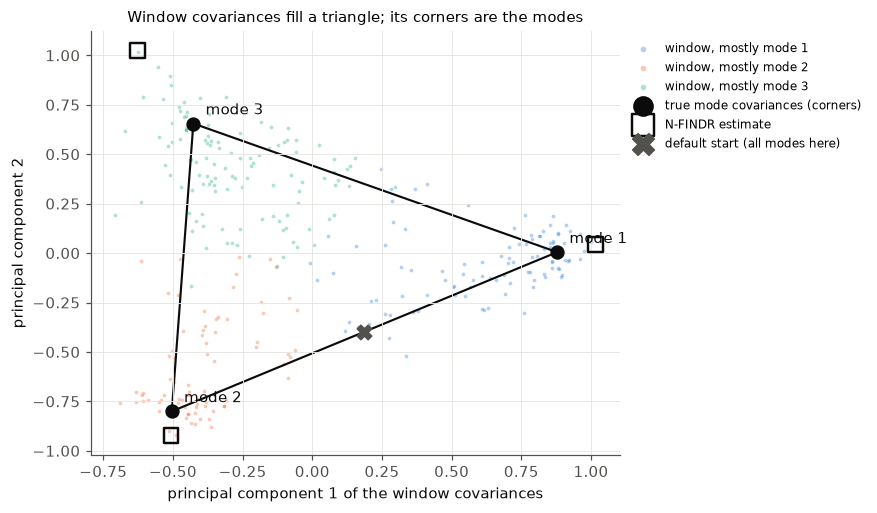

N-FINDR estimate vs truth, largest absolute error in any entry, per true mode: [0.14 0.11 0.37]
(true variances are 0.3 to 2.0)


In [2]:
# Toy: 2 channels, 3 modes with very different covariances
D_toy = np.array([
    [[1.0, 0.8], [0.8, 1.0]],    # mode 1: channels move together
    [[1.0, -0.8], [-0.8, 1.0]],  # mode 2: channels move in opposition
    [[2.0, 0.0], [0.0, 0.3]],    # mode 3: channel 1 dominates
])
np.random.seed(1)   # the simulation classes use NumPy's global random state
toy = MixedSine_MVN(
    n_samples=60000, relative_activation=[1.0, 1.0, 1.0], amplitudes=[5, 5, 5],
    frequencies=[0.11, 0.17, 0.23], sampling_frequency=250, means="zero", covariances=D_toy,
)
x_toy, a_toy = toy.time_series, toy.mode_time_course
W = 200
S_toy = vech(window_moments([x_toy], W))       # (n_windows, 3)
A_toy = window_means([a_toy], W)               # true window-mean alpha (known in a simulation)

# Coordinates in the plane of the triangle (the top 2 principal components of the windows)
mu = S_toy.mean(0)
_, _, Vt = np.linalg.svd(S_toy - mu, full_matrices=False)
P = lambda v: (v - mu) @ Vt[:2].T
C_nf = nfindr_covariances([x_toy], 3, window_length=W, random_seed=0)

fig, ax = plt.subplots(figsize=(6.2, 5))
pts, dom = P(S_toy), A_toy.argmax(1)
for k, col in enumerate([BLUE, ORANGE, AQUA]):
    ax.scatter(*pts[dom == k].T, s=6, color=col, alpha=0.35, lw=0, label=f"window, mostly mode {k + 1}")
tri = P(vech(D_toy))
ax.fill(*tri.T, facecolor="none", edgecolor=INK, lw=1.4)
ax.scatter(*tri.T, s=70, color=INK, zorder=3, label="true mode covariances (corners)")
nf = P(vech(C_nf))
ax.scatter(*nf.T, s=90, facecolor="none", edgecolor=INK, lw=1.6, marker="s", zorder=3, label="N-FINDR estimate")
d0 = P(vech(np.eye(2)))
ax.scatter(*d0, s=90, color=MUTED, marker="X", zorder=3, label="default start (all modes here)")
for k, (px, py) in enumerate(tri):
    ax.annotate(f"mode {k + 1}", (px, py), xytext=(8, 6), textcoords="offset points", color=INK)
ax.set_xlabel("principal component 1 of the window covariances")
ax.set_ylabel("principal component 2")
ax.set_title("Window covariances fill a triangle; its corners are the modes", fontsize=10)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, markerscale=1.5)
plt.show()
err = np.abs(C_nf[:, None] - D_toy[None]).max((2, 3))     # [estimate, true mode]
r, c = linear_sum_assignment(err.T)
print("N-FINDR estimate vs truth, largest absolute error in any entry, per true mode:", np.round(err.T[r, c], 2))
print("(true variances are 0.3 to 2.0)")

**What the picture shows.**

- Each dot is one 200-sample window. The windows fill a triangle whose corners are the three true
  mode covariances (black dots). Windows dominated by one mode sit near its corner (about a third of
  the average distance of all windows); mixtures fill the middle.
- The scatter around the triangle is window noise: a covariance estimated from 200 samples is noisy,
  so about half of the windows fall outside the true triangle.
- **N-FINDR** (squares) finds the corners from the data alone, without knowing $\alpha$. Its estimates
  land a little beyond the true corners (largest error in any entry 0.14, 0.11 and 0.37), because the
  most extreme windows include some noise. Mode 3 has the largest variance, so its windows are the
  noisiest and its estimate is furthest out. Training corrects this.
- **The default start** (grey cross) puts *every* mode at the same point, the identity. Training then
  has to pull the modes apart toward different corners, and that is where it can go wrong.

## 4. The procedure, step by step

`osl_dynamics.models.initialization.nfindr_covariances(time_series, n_modes, window_length=20)` does:

1. **Window second moments.** Split each session into non-overlapping windows of $L$ samples
   and compute $s_W = \mathrm{vech}(S_W)$. With $p$ channels each is a vector of length $p(p+1)/2$
   (820 for $p=40$).
2. **Signal subspace.** The noise-free points lie in a $(K-1)$-dimensional flat region; the window
   noise is spread over all $p(p+1)/2$ directions. Principal component analysis keeps the top $K-1$
   directions, $y_W = V_{K-1}^\top (s_W - \bar s)$, which keeps the signal and drops most of the noise.
3. **Find the corners (N-FINDR, Winter 1999).** Choose the $K$ windows whose points span the simplex
   of largest volume, $\mathrm{vol} \propto |\det [\,1,\ y_{i_1};\ \dots;\ 1,\ y_{i_K}\,]|$. Start from
   $K$ random windows and keep replacing one vertex by the window that most increases the volume.
   The determinant is linear in each row, so all replacements of a vertex are scored at once.
   Repeat from 10 random starts and keep the largest simplex.
4. **Mixing weights of every window.** Express each window as a non-negative, sum-to-one mixture of the
   $K$ vertices (non-negative least squares, with the sum-to-one constraint as a heavily weighted
   extra row).
5. **Least-squares covariances from all windows.** Solve $\min_D \lVert S - A D\rVert_F^2$, where $A$
   holds the mixing weights. Each row of $D$ is one mode covariance. Floor the eigenvalues at 1% of
   their mean so every covariance is positive definite.
6. **Start DyNeMo there.** `Model.nfindr_initialization(data)` (or `init_method="nfindr"`) cuts the
   windows from the sequences the model is trained on, sets the covariances *and* their reset value,
   and then runs the same multi-start as `random_subset_initialization`: each candidate starts from
   the N-FINDR covariances with freshly drawn RNN weights. Training then proceeds as usual, and the
   covariances are still learnt.

**What step 5 does, precisely.** If no window is pure for a mode, the vertex N-FINDR picks for it is a
mixture, and so is the least-squares estimate: it equals the *expected* covariance of the purest
windows, not the pure mode. What step 5 adds is **denoising**: it pools all windows instead of using
one noisy 20-sample window. Pulling the estimate the rest of the way to the true corner is left to
DyNeMo's training, which now starts with every mode in its own, roughly right, direction.

Next, a harder case: 6 modes of very different strengths, 40 channels, 32 sessions of 400 samples.
We simulate 80 channels and 64 sessions and keep a random half of each, which leaves the weakest modes
close to the noise level.

In [3]:
rng = np.random.default_rng(7)
np.random.seed(7)
sim = MixedSine_MVN(
    n_samples=64 * 400, n_modes=6, n_channels=80,
    relative_activation=[1.0, 1.2, 1.4, 1.6, 1.8, 2.0], amplitudes=[6, 5, 4, 3, 2, 1],
    frequencies=[1.2, 2.2, 3.2, 4.2, 5.2, 6.2], sampling_frequency=250,
    means="zero", covariances="random",
)
sessions = rng.choice(64, 32, replace=False)
channels = np.sort(rng.choice(80, 40, replace=False))
x_all = sim.time_series.reshape(64, 400, 80)
a_all = sim.mode_time_course.reshape(64, 400, 6)
x = [x_all[i][:, channels].astype(np.float32) for i in sessions]
a_true = [a_all[i] for i in sessions]
D_true = sim.obs_mod.covariances[:, channels][:, :, channels]
alpha_true = np.concatenate(a_true)
K, p = 6, len(channels)

print(f"{len(x)} sessions x {x[0].shape[0]} samples x {p} channels, {K} modes")
print("mean alpha per true mode:", np.round(alpha_true.mean(0), 3))
print("share of time with alpha > 0.5:", np.round((alpha_true > 0.5).mean(0), 3))

32 sessions x 400 samples x 40 channels, 6 modes
mean alpha per true mode: [0.265 0.223 0.171 0.139 0.101 0.101]
share of time with alpha > 0.5: [0.256 0.213 0.126 0.101 0.042 0.043]


Modes 5 and 6 are the weak ones: on average about 10% of the mixture each, and above 0.5 for only
about 4% of the time. These are the modes the default start tends to lose.

We now compare ways of choosing starting covariances, by how well each matches the true mode
covariances (correlation of the off-diagonal entries, best match per true mode): the default start,
the covariances of 6 random windows, the 6 windows N-FINDR picks, and N-FINDR's final least-squares
estimate.

In [4]:
iu1 = np.triu_indices(p, 1)


def cov_match(C):
    # Correlation of off-diagonal entries with each true mode, after the best one-to-one matching
    corr = np.corrcoef(D_true[:, iu1[0], iu1[1]], C[:, iu1[0], iu1[1]])[:K, K:]
    r, c = linear_sum_assignment(-corr)
    out = np.empty(K)
    out[r] = corr[r, c]
    return out


W = 20
S_mat = window_moments(x, W)
A_win = window_means(a_true, W)
S = vech(S_mat)

# Random windows, averaged over 200 draws
r_random = np.mean([cov_match(S_mat[rng.choice(len(S_mat), K, replace=False)]) for _ in range(200)], 0)

# N-FINDR's picked windows: rebuild steps 2-3 here to see which windows it picks
mu = S.mean(0)
eigval, eigvec = np.linalg.eigh((S - mu).T @ (S - mu) / len(S))
eigval, eigvec = eigval[::-1], eigvec[:, ::-1]
Y = np.c_[np.ones(len(S)), (S - mu) @ eigvec[:, : K - 1]]
best, best_vol = None, -np.inf
for _ in range(10):
    idx = rng.choice(len(Y), K, replace=False)
    for _ in range(100):
        improved = False
        for j in range(K):
            M = Y[idx]
            vols = np.abs(Y @ (np.linalg.det(M) * np.linalg.inv(M)[:, j]))
            if vols.max() > abs(np.linalg.det(M)) * (1 + 1e-9):
                idx[j], improved = int(vols.argmax()), True
        if not improved:
            break
    if abs(np.linalg.det(Y[idx])) > best_vol:
        best, best_vol = idx.copy(), abs(np.linalg.det(Y[idx]))
r_picks = cov_match(S_mat[best])

# The full method (library function)
C_nfindr = nfindr_covariances(x, K, window_length=W, random_seed=0)
r_nfindr = cov_match(C_nfindr)

print(f"{len(S)} windows of {W} samples, each a vector of {S.shape[1]} numbers")
print("default start: every mode = diag(1 + small noise); off-diagonals are 0, so no match to any mode")
print("purity of the windows N-FINDR picked (largest true window-mean alpha):", np.round(A_win[best].max(1), 2))
for name, r in [("6 random windows", r_random), ("N-FINDR picked windows", r_picks), ("N-FINDR estimate (used)", r_nfindr)]:
    print(f"{name:>24}: cov r per true mode {np.round(r, 2)}")

640 windows of 20 samples, each a vector of 820 numbers
default start: every mode = diag(1 + small noise); off-diagonals are 0, so no match to any mode
purity of the windows N-FINDR picked (largest true window-mean alpha): [0.89 0.63 0.58 0.69 0.58 0.98]
        6 random windows: cov r per true mode [0.35 0.3  0.24 0.19 0.13 0.12]
  N-FINDR picked windows: cov r per true mode [0.47 0.42 0.37 0.34 0.34 0.37]
 N-FINDR estimate (used): cov r per true mode [0.97 0.96 0.92 0.9  0.74 0.74]


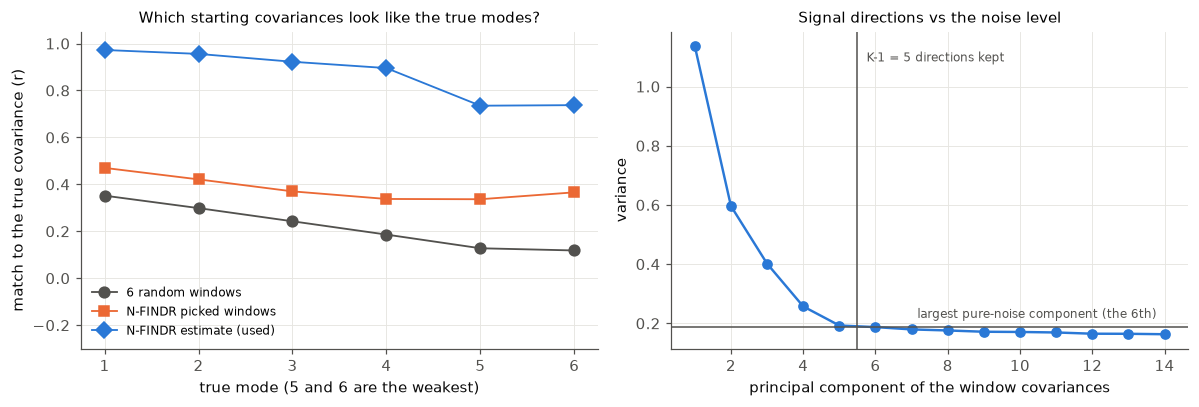

variance of components 1-8: [1.136 0.596 0.402 0.257 0.193 0.187 0.179 0.176] | largest pure-noise component: 0.187


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axes[0]
modes = np.arange(1, K + 1)
for r, col, mk, name in [(r_random, MUTED, "o", "6 random windows"), (r_picks, ORANGE, "s", "N-FINDR picked windows"),
                         (r_nfindr, BLUE, "D", "N-FINDR estimate (used)")]:
    ax.plot(modes, r, color=col, marker=mk, ms=7, lw=1.2, label=name)
ax.set_xticks(modes)
ax.set_xlabel("true mode (5 and 6 are the weakest)")
ax.set_ylabel("match to the true covariance (r)")
ax.set_ylim(-0.3, 1.05)
ax.set_title("Which starting covariances look like the true modes?", fontsize=10)
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
n_show = 14
ax.plot(np.arange(1, n_show + 1), eigval[:n_show], color=BLUE, marker="o", ms=6)
# With K modes the signal spans only K-1 directions, so component K onwards is pure window noise
noise = eigval[K - 1]
ax.axhline(noise, color=MUTED, lw=1)
ax.annotate(f"largest pure-noise component (the {K}th)", (n_show, noise), xytext=(-5, 6), textcoords="offset points",
            ha="right", color=MUTED, fontsize=8)
ax.axvline(K - 1 + 0.5, color=MUTED, lw=1)
ax.annotate(f"K-1 = {K - 1} directions kept", (K - 1 + 0.5, eigval[0]), xytext=(6, -10), textcoords="offset points",
            color=MUTED, fontsize=8)
ax.set_xlabel("principal component of the window covariances")
ax.set_ylabel("variance")
ax.set_title("Signal directions vs the noise level", fontsize=10)
plt.tight_layout()
plt.show()
print("variance of components 1-8:", np.round(eigval[:8], 3), f"| largest pure-noise component: {noise:.3f}")

**What these show.**

- **Random windows are poor starting points** (r 0.12-0.35). Each is a noisy mixture of modes, and
  several can come from the same strong mode while others get none.
- **The windows N-FINDR picks** are fairly pure (largest true mixing weight 0.58-0.98), but each is
  still a noisy 20-sample estimate (r 0.34-0.47). They fix the *geometry*: which direction each mode
  is in.
- **The least-squares step pools all 640 windows** and raises the match to r 0.90-0.97 for modes 1-4
  and 0.74 for modes 5 and 6. This is the starting point DyNeMo gets.
- **The spectrum shows why the weak modes are the hard part.** With 6 modes the signal spans only 5
  directions, so the 6th component onwards is pure noise (variance 0.187). The 5th component (0.193)
  is only just above it: the cloud barely reaches out in the weakest signal direction. Here that is
  enough to place modes 5 and 6 roughly; with a little less signal it would not be (section 7).

## 5. Training DyNeMo from three starts

Same data and the same settings for every run (sequence length 200, batch 16, learning rate 0.01,
200 epochs with 100 of KL annealing, 10 initialisations of 2 epochs). The only difference is where
the covariances start:

- **default**: `init_method="random_subset"`, the current default;
- **N-FINDR**: `init_method="nfindr"`;
- **truth**: the true covariances, passed as `initial_covariances` (only possible in a simulation;
  it shows what a good optimum looks like).

In every run the covariances are learnt.

In [6]:
from osl_dynamics.data import Data
from osl_dynamics.models.dynemo import Config, Model
from osl_dynamics.utils import set_random_seed

data = Data(x, store_dir=tempfile.mkdtemp())


def train(start, seed=0):
    set_random_seed(seed)
    config = Config(
        n_modes=K, n_channels=p, sequence_length=200,
        inference_n_units=64, inference_normalization="layer",
        model_n_units=64, model_normalization="layer",
        learn_alpha_temperature=True, initial_alpha_temperature=1.0,
        learn_means=False, learn_covariances=True,
        initial_covariances=D_true.astype(np.float32) if start == "truth" else None,
        do_kl_annealing=True, kl_annealing_curve="tanh", kl_annealing_sharpness=10,
        n_kl_annealing_epochs=100, batch_size=16, learning_rate=0.01, lr_decay=0.1, n_epochs=200,
        init_method="nfindr" if start == "nfindr" else "random_subset", n_init=10, n_init_epochs=2,
    )
    model = Model(config)
    model.set_regularizers(data)
    model.train(data, verbose=0)   # initialisation, then full training
    alpha = np.concatenate(model.get_alpha(data, verbose=0))
    return {"alpha": alpha, "covs": model.get_covariances(), "free_energy": float(model.free_energy(data))}


def alpha_match(alpha):
    # Correlation of each true mode's alpha with its best-matching fitted mode (one-to-one)
    corr = np.nan_to_num(np.corrcoef(alpha_true.T, alpha.T)[:K, K:])
    r, c = linear_sum_assignment(-corr)
    out = np.empty(K)
    out[r] = corr[r, c]
    return out, c


fits = {}
for start in ["default", "nfindr", "truth"]:
    fits[start] = train(start)
    r_alpha, _ = alpha_match(fits[start]["alpha"])
    fits[start]["alpha_r"], fits[start]["cov_r"] = r_alpha, cov_match(fits[start]["covs"])
    print(f"{start:>8} start: free energy {fits[start]['free_energy']:.3f} per time point | alpha r per true mode "
          f"{np.round(r_alpha, 2)} | cov r {np.round(fits[start]['cov_r'], 2)}")
data.delete_dir()

# The free energy is averaged over time points, so small differences add up over the data
n_total = sum(len(xi) for xi in x)
for start in ["default", "nfindr"]:
    diff = fits[start]["free_energy"] - fits["truth"]["free_energy"]
    print(f"{start:>8} start minus truth start: {diff:+.3f} per time point, {diff * n_total:+.0f} over all {n_total} time points")

 default start: free energy 48.972 per time point | alpha r per true mode [ 0.99  0.96  0.9   0.88  0.33 -0.11] | cov r [ 0.98  0.71  0.73  0.83 -0.    0.18]


  nfindr start: free energy 48.726 per time point | alpha r per true mode [0.99 0.98 0.97 0.96 0.86 0.91] | cov r [0.98 0.97 0.96 0.92 0.72 0.75]


   truth start: free energy 48.704 per time point | alpha r per true mode [0.99 0.98 0.97 0.96 0.9  0.94] | cov r [0.98 0.97 0.96 0.92 0.76 0.81]
 default start minus truth start: +0.267 per time point, +3421 over all 12800 time points
  nfindr start minus truth start: +0.022 per time point, +277 over all 12800 time points


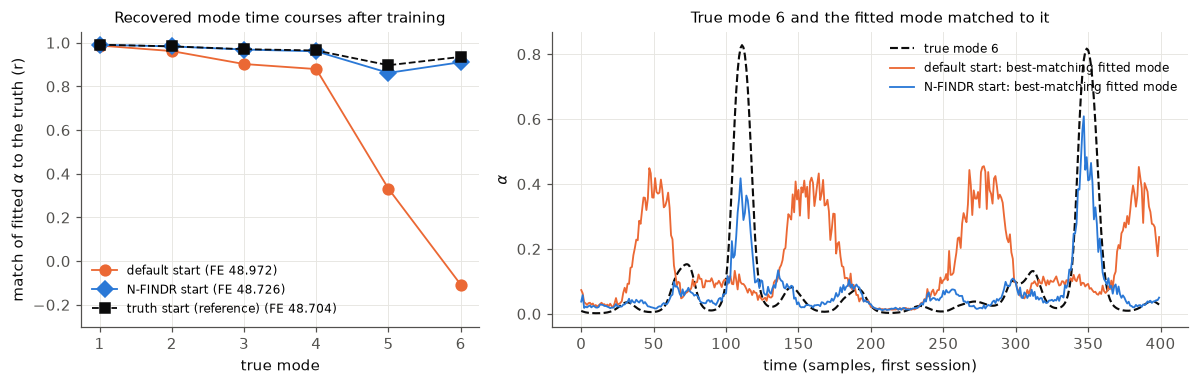

In [7]:
STARTS = [("default", ORANGE, "o", "-", "default start"), ("nfindr", BLUE, "D", "-", "N-FINDR start"),
          ("truth", INK, "s", "--", "truth start (reference)")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})

ax = axes[0]
for start, col, mk, ls, name in STARTS:
    ax.plot(modes, fits[start]["alpha_r"], color=col, marker=mk, ms=7, lw=1.2, ls=ls,
            label=f"{name} (FE {fits[start]['free_energy']:.3f})")
ax.set_xticks(modes)
ax.set_ylim(-0.3, 1.05)
ax.set_xlabel("true mode")
ax.set_ylabel(r"match of fitted $\alpha$ to the truth (r)")
ax.set_title("Recovered mode time courses after training", fontsize=10)
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
weak = int(np.argmax(fits["nfindr"]["alpha_r"] - fits["default"]["alpha_r"]))   # where the two starts differ most
span = slice(0, 400)
ax.plot(alpha_true[span, weak], color=INK, lw=1.4, ls="--", label=f"true mode {weak + 1}")
for start, col, _, _, name in STARTS[:2]:
    _, cols = alpha_match(fits[start]["alpha"])
    ax.plot(fits[start]["alpha"][span, cols[weak]], color=col, lw=1.2, label=f"{name}: best-matching fitted mode")
ax.set_xlabel("time (samples, first session)")
ax.set_ylabel(r"$\alpha$")
ax.set_title(f"True mode {weak + 1} and the fitted mode matched to it", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

**What happened.**

- All three starts recover the four strongest modes ($\alpha$ r 0.88-0.99).
- **The default start loses the two weakest modes.** Their $\alpha$ match only r 0.33 and -0.11, and
  no fitted covariance resembles them (r -0.00 and 0.18). Its covariances for modes 2-4 are also
  less clean (r 0.71-0.83 against 0.92-0.97 for the other two starts).
- **The N-FINDR start recovers all six modes** ($\alpha$ r 0.86-0.99, covariance r 0.72-0.98), close to
  the start from the true covariances ($\alpha$ r 0.90-0.99, covariance r 0.76-0.98).
- **Free energy.** All three runs minimise the same objective on the same data. The default start
  ends 0.267 per time point (3421 in total) above the truth start, so it is stuck in a worse optimum.
  The N-FINDR start ends 0.022 per time point (277 in total) above it.
- The right panel shows the true mode where the two starts differ most (mode 6), with the fitted mode
  matched to it in each run: the N-FINDR fit follows it (r 0.91), the default fit's best match does
  not (r -0.11).

## 6. Why it works better

- **It breaks the symmetry with the data, not with random noise.** The default start makes all modes
  identical and relies on small random differences, amplified by the early training, to decide which
  mode becomes which. N-FINDR starts each mode near a *different* corner of the data, so there is
  nothing for the modes to fight over.
- **It gives the weak modes a place to go.** A weak mode that never dominates still pushes the cloud of
  windows out in its own direction. N-FINDR gives it a starting covariance in that direction, so it
  doesn't have to be discovered by a fitted mode that has already settled elsewhere.
- **It skips the greedy phase.** With KL annealing, the first part of training is free to allocate
  modes greedily. Starting near the corners means that phase starts from a good layout.
- **It is cheap and uses only the training data.** One pass over the windows plus a small search:
  under a second for the data above, about 5 s for 500 sessions x 1200 samples x 50 channels at K = 8.

**In a larger simulation study** (6-mode soft mixtures like the one above; not run here):

| case | default start | N-FINDR start |
|---|---|---|
| full data with a dead-mode optimum (3 simulations, 2 seeds each) | 3 of 13 runs recover all modes | 6 of 6 recover all modes |
| full data, free energy (one of those simulations) | mode 6 dead, free energy above the truth start's | free energy below the truth start's |
| bi-cross-validation with 100 folds, K = 1-16 | 8-16 broken folds per K; jagged curve with its maximum at K = 13 | 0-1 broken folds; held-out log-likelihood +0.07 to +0.26 per sample at every K; smooth curve with a plateau at K = 5-8 |

## 7. Limitations

- **Modes at the noise level can't be found this way.** The corner for a mode is only visible if the
  cloud of windows reaches out in its direction by more than the window noise. When the corresponding
  principal component is at the noise level (section 4), N-FINDR has no corner to find. DyNeMo itself
  can still hold such a mode when it starts near it (the per-sample likelihood with the RNN prior is
  more efficient than 20-sample windows), so this is a limit of the initialisation, not of the model.
- **Modes that are never pure give mixed corners.** The vertices are the purest windows that exist.
  If a mode is always mixed with others, its starting covariance is a blend, and training has to do
  the rest.
- **Window length is a trade-off.** Longer windows have less noise but their mixing weights are
  averaged over more time, so they are less pure. 20 samples suits the 250 Hz simulations here; slower,
  fMRI-like data did better with 40-80 samples. Windows are cut within each training sequence, so
  `window_length` should be at most `sequence_length` (ideally a divisor of it).
- **Zero means.** The method uses second moments, so it assumes zero means (`learn_means=False`).
  With `learn_means=True` the means are not initialised and a warning is given.
- **Fixed or given covariances.** If the covariances are not learnt, or `initial_covariances` are
  passed, they are left as they are and `nfindr_initialization` is the same as
  `random_subset_initialization` (with a warning).
- **K above the true number.** Extra vertices then come from noise; DyNeMo can still switch the extra
  modes off during training. K below the true number: the best K-mode solution is a set of blends, not
  the corners, so the start can be slightly worse than the default (we saw small losses at K = 2).

## 8. How to use it

Through the config:

```python
from osl_dynamics.models.dynemo import Config, Model

config = Config(
    n_modes=6, n_channels=40, learn_means=False, learn_covariances=True,
    init_method="nfindr", n_init=10, n_init_epochs=2,
    ...,
)
model = Model(config)
model.set_regularizers(data)
model.train(data)   # N-FINDR initialisation (window_length=20), then full training
```

Or call the initialisation directly, e.g. to change the window length:

```python
model.nfindr_initialization(data, window_length=40, n_init=10, n_epochs=2)
model.fit(data)
```

In the config API, pass `init_method` in `config_kwargs` and the window length in `init_kwargs`:

```yaml
train_dynemo:
    config_kwargs:
        n_modes: 6
        learn_means: False
        learn_covariances: True
        init_method: nfindr
    init_kwargs:
        n_init: 10
        n_epochs: 2
        window_length: 20
```

To get the starting covariances without a model:

```python
from osl_dynamics.models.initialization import nfindr_covariances

covs = nfindr_covariances(time_series, n_modes=6, window_length=20)   # list of (n_samples, n_channels) arrays
```

**References.** M. E. Winter, "N-FINDR: an algorithm for fast autonomous spectral end-member
determination in hyperspectral data", Proc. SPIE 3753 (1999). J. M. Bioucas-Dias et al.,
"Hyperspectral unmixing overview: geometrical, statistical, and sparse regression-based approaches",
IEEE J-STARS 5 (2012).